# ANN Classifier for Seismic Signals
This notebook trains a lightweight Artificial Neural Network (ANN) on a single component (e.g., X-axis) of the raw 3D seismic signal to classify animal footsteps (Class 1 vs Class 6).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import netCDF4 as nc
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')

PyTorch version : 2.8.0+cu128
CUDA available  : True


## Setup Device

In [2]:
# ── DGX Multi-GPU Auto-Selection: Pick the GPU with the most free VRAM ──
if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f'GPU count       : {num_gpus}')
    best_gpu_idx = 0
    max_free_mem = 0
    
    print('\nChecking VRAM availability across all GPUs:')
    for i in range(num_gpus):
        try:
            free_mem, total_mem = torch.cuda.mem_get_info(i)
            free_gb  = free_mem  / (1024**3)
            total_gb = total_mem / (1024**3)
            print(f'  GPU {i}: {torch.cuda.get_device_name(i):22s} | Free: {free_gb:5.1f} GB / {total_gb:5.1f} GB')
            if free_mem > max_free_mem:
                max_free_mem = free_mem
                best_gpu_idx = i
        except Exception as e:
            print(f'  GPU {i}: Could not query memory ({e})')
            
    device = torch.device(f'cuda:{best_gpu_idx}')
    torch.cuda.set_device(device)
    torch.cuda.empty_cache()   # Clear any leftover cached memory
    print(f'\n🚀 Automatically selected GPU {best_gpu_idx} ({torch.cuda.get_device_name(best_gpu_idx)}) with {max_free_mem/(1024**3):.1f} GB free VRAM!')
else:
    device = torch.device('cpu')
    print('Using device    : cpu')

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

GPU count       : 8

Checking VRAM availability across all GPUs:
  GPU 0: NVIDIA A100-SXM4-80GB  | Free:  33.6 GB /  79.2 GB
  GPU 1: NVIDIA A100-SXM4-80GB  | Free:   0.7 GB /  79.2 GB
  GPU 2: NVIDIA A100-SXM4-80GB  | Free:  65.6 GB /  79.2 GB
  GPU 3: NVIDIA A100-SXM4-80GB  | Free:  61.9 GB /  79.2 GB
  GPU 4: NVIDIA A100-SXM4-80GB  | Free:  66.3 GB /  79.2 GB
  GPU 5: NVIDIA A100-SXM4-80GB  | Free:  67.1 GB /  79.2 GB
  GPU 6: NVIDIA A100-SXM4-80GB  | Free:  59.8 GB /  79.2 GB
  GPU 7: NVIDIA A100-SXM4-80GB  | Free:  65.6 GB /  79.2 GB

🚀 Automatically selected GPU 5 (NVIDIA A100-SXM4-80GB) with 67.1 GB free VRAM!


## Load Dataset and Select Component

In [3]:
# Load Dataset
FILE_PATH = 'dset_allspec_150_chunks_clean.nc'

if not os.path.exists(FILE_PATH):
    FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

try:
    dataset = nc.Dataset(FILE_PATH, mode='r')
except:
    FILE_PATH = '/Users/aaronr/Desktop/DUK/PROJECT/SIGNAL_ PROCESSING_PROJECT/dset_allspec_150_chunks_clean.nc'
    dataset = nc.Dataset(FILE_PATH, mode='r')

all_chunks = dataset['chunk'][:]
all_labels = dataset['class'][:].astype(int)

# Select Classes 1 and 6
SELECTED_CLASSES = [1, 6]
mask = np.isin(all_labels, SELECTED_CLASSES)

selected_chunks = all_chunks[mask]
selected_labels = all_labels[mask]
dataset.close()

# Extract single component
# 0: X, 1: Y, 2: Z
# We use X axis here as an example
component_idx = 0 
X = selected_chunks[:, component_idx, :]
y = selected_labels

# Map labels to 0 and 1
label_map = {1: 0, 6: 1}
y = np.array([label_map[l] for l in y])

print(f"Extracted Component {component_idx}")
print(f"X shape: {X.shape}, y shape: {y.shape}")

Extracted Component 0
X shape: (66814, 2048), y shape: (66814,)


## Data Preprocessing

In [4]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the data (very important for ANN convergence)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# PyTorch Dataset
class SeismicDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = SeismicDataset(X_train, y_train)
test_dataset = SeismicDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

## Define ANN Model

In [5]:
class ANNClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(ANNClassifier, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.bn1 = nn.BatchNorm1d(hidden_size)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)
        
        self.fc2 = nn.Linear(hidden_size, hidden_size // 2)
        self.bn2 = nn.BatchNorm1d(hidden_size // 2)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.5)
        
        self.fc3 = nn.Linear(hidden_size // 2, num_classes)
        
    def forward(self, x):
        out = self.fc1(x)
        out = self.bn1(out)
        out = self.relu1(out)
        out = self.dropout1(out)
        
        out = self.fc2(out)
        out = self.bn2(out)
        out = self.relu2(out)
        out = self.dropout2(out)
        
        out = self.fc3(out)
        return out

input_size = X.shape[1] # 2048
hidden_size = 512
num_classes = 2

model = ANNClassifier(input_size, hidden_size, num_classes).to(device)
print(model)

ANNClassifier(
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (bn1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc3): Linear(in_features=256, out_features=2, bias=True)
)


## Training Loop

Class weights: tensor([0.5346, 7.7308], device='cuda:5')
Starting Training...
Epoch [1/50], Loss: 0.7242, Accuracy: 66.51%
Epoch [2/50], Loss: 0.6793, Accuracy: 74.65%
Epoch [3/50], Loss: 0.6691, Accuracy: 75.22%
Epoch [4/50], Loss: 0.6532, Accuracy: 73.23%
Epoch [5/50], Loss: 0.6450, Accuracy: 72.21%
Epoch [6/50], Loss: 0.6339, Accuracy: 73.11%
Epoch [7/50], Loss: 0.6228, Accuracy: 72.63%
Epoch [8/50], Loss: 0.6128, Accuracy: 72.95%
Epoch [9/50], Loss: 0.5958, Accuracy: 73.75%
Epoch [10/50], Loss: 0.5853, Accuracy: 73.94%
Epoch [11/50], Loss: 0.5733, Accuracy: 74.22%
Epoch [12/50], Loss: 0.5598, Accuracy: 74.57%
Epoch [13/50], Loss: 0.5506, Accuracy: 75.23%
Epoch [14/50], Loss: 0.5428, Accuracy: 75.63%
Epoch [15/50], Loss: 0.5382, Accuracy: 75.97%
Epoch [16/50], Loss: 0.5323, Accuracy: 76.16%
Epoch [17/50], Loss: 0.5204, Accuracy: 76.01%
Epoch [18/50], Loss: 0.5097, Accuracy: 77.23%
Epoch [19/50], Loss: 0.4972, Accuracy: 77.11%
Epoch [20/50], Loss: 0.5158, Accuracy: 76.43%
Epoch [21/5

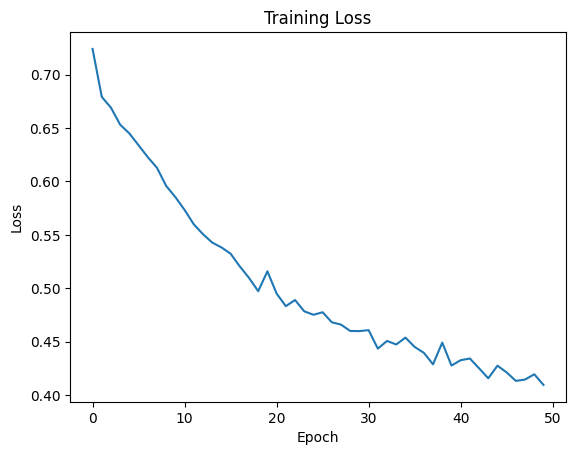

In [6]:
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Class weights: {class_weights}")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 50
train_losses = []

print("Starting Training...")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)
    epoch_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%")

plt.plot(train_losses)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## Evaluation


Classification Report:
                      precision    recall  f1-score   support

  Class 1 (Elephant)       0.93      0.44      0.60     12499
Class 6 (Wildebeest)       0.06      0.53      0.11       864

            accuracy                           0.45     13363
           macro avg       0.50      0.48      0.35     13363
        weighted avg       0.87      0.45      0.57     13363



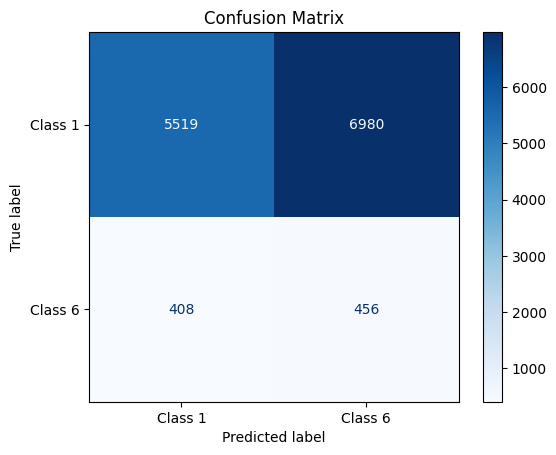

In [7]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=['Class 1 (Elephant)', 'Class 6 (Wildebeest)']))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 1', 'Class 6'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()